# 09 · Compare attention and FFN routing

Read the paired contrasts before interpreting a ranking. Dense attention controls distinguish the benefit of attention itself from the benefit of head routing.

## Saved-run finding

MoH has lower mean one-step error than standard attention: 0.010786 versus 0.011013. The mean paired relative change is -2.07%, with lower error in 3/3 seeds.

Full preset with three seeds and 40 epochs. This is an initial controlled result. The default interactive preset is smoke. Recompute before drawing conclusions after changing settings.

## Setup

Run cells in order. Default: smoke. Set `TWILIGHT_CONFIG=configs/attention_experiment.yaml` for the full preset.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.experiment import load_metrics, load_diagnostics, verify_provenance
from twilight_moe.attention import ATTENTION_NAMES
from twilight_moe.plotting import style, save_figure, COLORS
config_path = os.environ.get('TWILIGHT_CONFIG', 'configs/attention_smoke.yaml')
cfg = load_config(config_path)
if 'attention' not in cfg:
    cfg = load_config('configs/attention_smoke.yaml')
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'], '| epochs:', cfg['training']['epochs'])
print('Data:', cfg['data_root'])

Preset: attention_comparison_v1 | seeds: [7, 17, 27] | epochs: 40
Data: E:/HarunoKen/Twilight_MoE_Dynamics


## Load reviewed results

Source hashes must match every family and seed. The full preset is an initial benchmark, not a general verdict on MoH.

In [2]:
assert verify_provenance(cfg)
results = load_metrics(cfg)
paired = results.pivot(index='seed', columns='model', values='test_mse')
summary = results.groupby('model')['test_mse'].agg(['mean','std']).reindex(cfg['models'])
display(summary.round(6))

,mean,std
model,,
dense_active,0.011131,0.000212
dense_total,0.011068,0.000165
moe,0.011466,0.000132
random,0.011705,0.000192
oracle,0.006671,0.000045
attn_dense,0.011013,0.000083
attn_active,0.010961,0.000197
attn_total,0.010813,0.000108
attn_moh,0.010786,0.000181


## One-step comparison

Bars show seed means. Individual markers show seed variation, not confidence intervals. The oracle has privileged labels.

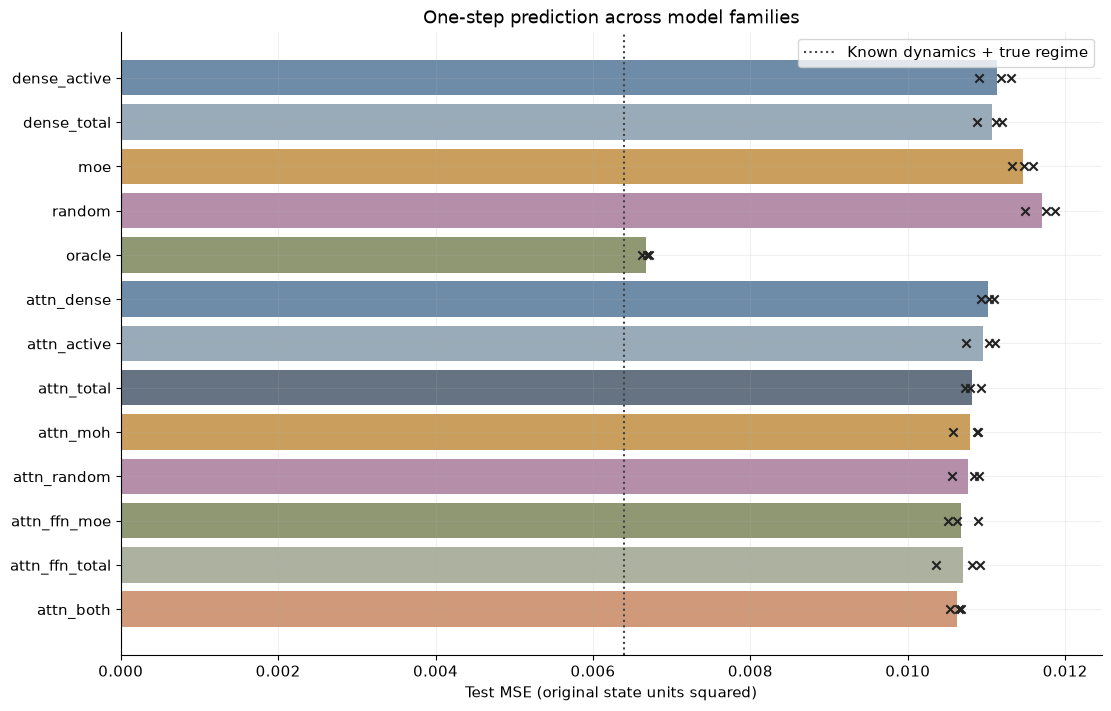

In [3]:
fig, ax = plt.subplots(figsize=(11, 7))
names = cfg['models']
ax.barh(names, summary['mean'], color=[COLORS[n] for n in names], alpha=.7)
for i, name in enumerate(names):
    ax.scatter(paired[name], np.full(len(paired), i), marker='x', color='#222222', zorder=3)
ax.axvline(results.known_dynamics_mse.mean(), color='#444444', linestyle=':', label='Known dynamics + true regime')
ax.set(xlabel='Test MSE (original state units squared)', title='One-step prediction across model families', xlim=(0,None))
ax.invert_yaxis()
ax.legend()
save_figure(fig, cfg, 'attention_one_step_comparison')
plt.show()

## Paired routing contrasts

Negative differences favor the first model. Capacity controls are separate from the common-backbone 2×2 comparison.

seed,7,17,27
attn_moh minus attn_dense,-0.000130,-0.000205,-0.000348
attn_moh minus attn_total,0.000175,-0.000047,-0.000209
attn_moh minus attn_active,-0.000140,-0.000223,-0.000161
attn_moh minus attn_random,-0.000013,0.000043,0.000020
attn_ffn_moe minus attn_dense,-0.000406,-0.000196,-0.000409
attn_ffn_moe minus attn_ffn_total,-0.000191,-0.000028,0.000157
attn_both minus attn_ffn_moe,0.000057,-0.000242,0.000018
attn_both minus attn_moh,-0.000219,-0.000234,-0.000043


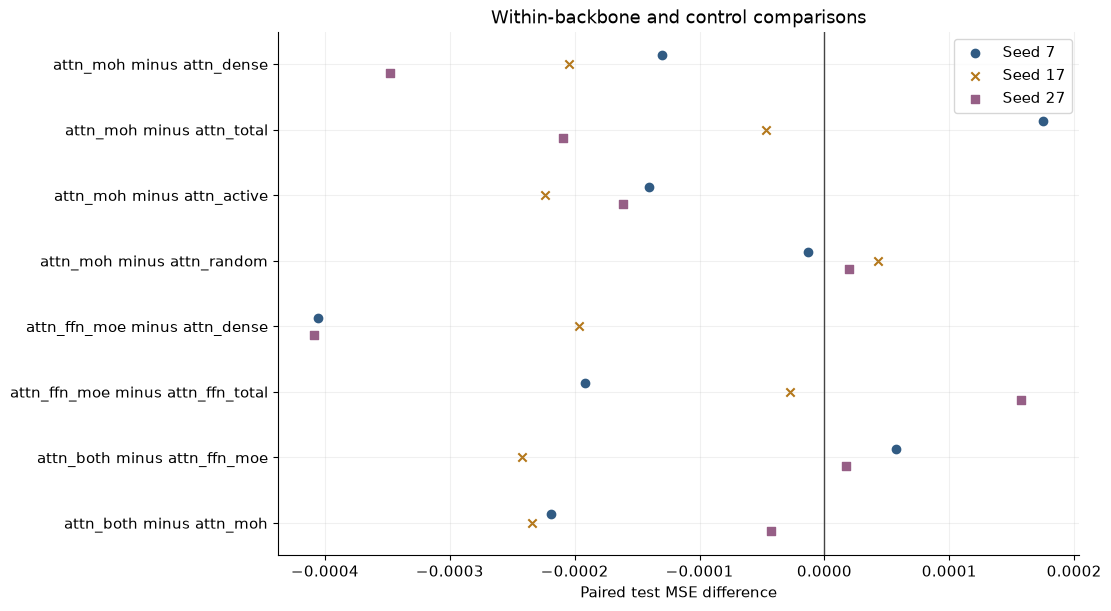

In [4]:
contrasts = [('attn_moh','attn_dense'), ('attn_moh','attn_total'),
             ('attn_moh','attn_active'), ('attn_moh','attn_random'),
             ('attn_ffn_moe','attn_dense'), ('attn_ffn_moe','attn_ffn_total'),
             ('attn_both','attn_ffn_moe'), ('attn_both','attn_moh')]
deltas = pd.DataFrame({f'{a} minus {b}':paired[a]-paired[b] for a,b in contrasts})
display(deltas.T.round(6))
fig, ax = plt.subplots(figsize=(11, 6))
for j, (seed, row) in enumerate(deltas.iterrows()):
    ax.scatter(row.values, np.arange(len(row))+(j-(len(deltas)-1)/2)*.13,
               label=f'Seed {seed}', marker=['o','x','s'][j%3], color=['#315b83','#b47719','#965f86'][j%3])
ax.axvline(0, color='#444444', linewidth=1)
ax.set(yticks=np.arange(len(deltas.columns)), yticklabels=deltas.columns,
       xlabel='Paired test MSE difference', title='Within-backbone and control comparisons')
ax.invert_yaxis()
ax.legend()
save_figure(fig, cfg, 'attention_paired_contrasts')
plt.show()

## Switch adaptation

Average seed-level curves. Each episode stops at the next switch, so later lags have fewer eligible episodes. The lower panel shows support.

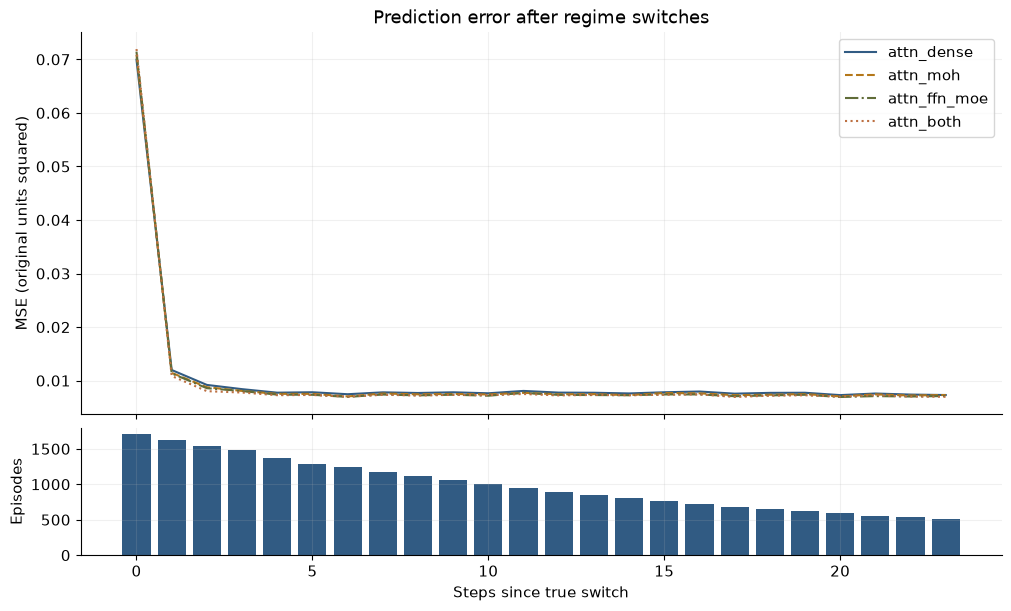

In [5]:
selected = ['attn_dense','attn_moh','attn_ffn_moe','attn_both']
diagnostics = {n:[load_diagnostics(cfg,n,seed) for seed in cfg['seeds']] for n in selected}
fig, axes = plt.subplots(2,1,figsize=(10,6),sharex=True,height_ratios=[3,1])
for i, name in enumerate(selected):
    curve = np.mean([x['adaptation_mse'] for x in diagnostics[name]], axis=0)
    axes[0].plot(curve, label=name, color=COLORS[name], linestyle=['-','--','-.',':'][i])
counts = np.sum([x['adaptation_counts'] for x in diagnostics['attn_dense']], axis=0)
axes[0].set(title='Prediction error after regime switches', ylabel='MSE (original units squared)')
axes[0].legend()
axes[1].bar(np.arange(len(counts)),counts,color='#315b83')
axes[1].set(xlabel='Steps since true switch',ylabel='Episodes')
save_figure(fig,cfg,'attention_switch_adaptation')
plt.show()

## Recursive forecasts

No future observed states enter ordinary models. Oracle and persistence remain available in the full metric files.

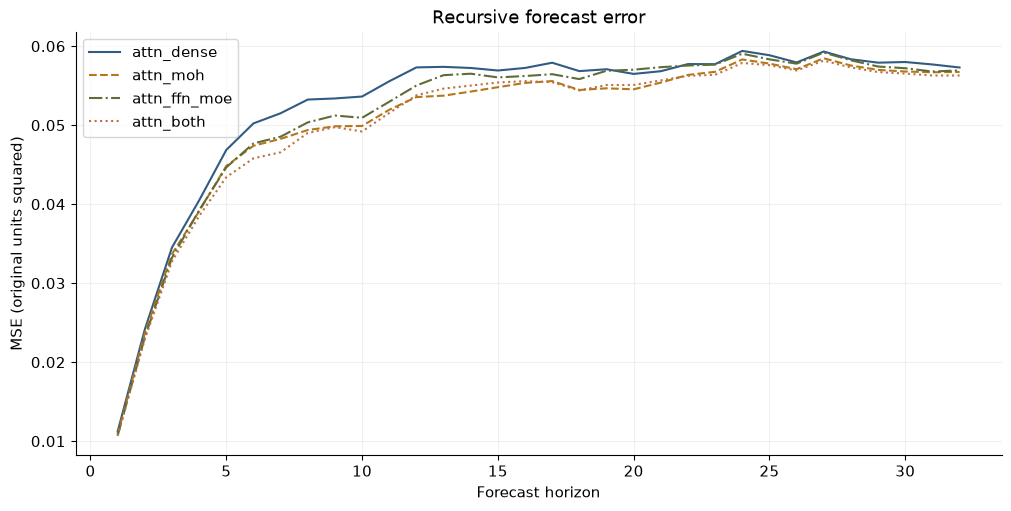

,switch_mse,recovered_fraction,recovery_delay_steps,rollout_mean_mse
model,,,,
attn_active,0.070505,0.764143,2.705203,0.051538
attn_both,0.071928,0.778187,2.507343,0.050514
attn_dense,0.069948,0.765227,2.690469,0.052693
attn_ffn_moe,0.071437,0.769358,2.683253,0.051638
attn_ffn_total,0.071034,0.767078,2.624826,0.051934
attn_moh,0.070824,0.775768,2.676281,0.050773
attn_random,0.071015,0.767051,2.558963,0.050855
attn_total,0.071463,0.767034,2.748098,0.051816
dense_active,0.070248,0.764174,2.652261,0.057350


In [6]:
fig, ax = plt.subplots(figsize=(10,5))
for i,name in enumerate(selected):
    curve = np.mean([x['rollout_mse'] for x in diagnostics[name]],axis=0)
    ax.plot(np.arange(1,len(curve)+1),curve,label=name,color=COLORS[name],linestyle=['-','--','-.',':'][i])
ax.set(xlabel='Forecast horizon',ylabel='MSE (original units squared)',title='Recursive forecast error')
ax.legend()
save_figure(fig,cfg,'attention_rollout_comparison')
plt.show()
display(results.groupby('model')[['switch_mse','recovered_fraction','recovery_delay_steps','rollout_mean_mse']].mean().round(6))

## Interpretation

The comparison tests a fixed configuration without test-driven tuning. A routing win does not show that the dataset requires attention, and a loss does not invalidate MoH. Three seeds change both data and initialization. Read the generated attention comparison log for the measured conclusion.